In [1]:
# === SETUP: Run this first ===
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Beautiful plot settings
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams.update({
    'figure.figsize': (14, 6),
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'figure.dpi': 100,
})

print('Setup complete!')

Setup complete!


In [2]:
# === LOAD ALL DATA ===
train = pd.read_csv('dataset/train.csv')
test = pd.read_csv('dataset/test.csv')
original = pd.read_csv('dataset/data.csv')

print(f'Train shape:    {train.shape[0]:>10,} rows x {train.shape[1]} columns')
print(f'Test shape:     {test.shape[0]:>10,} rows x {test.shape[1]} columns')
print(f'Original shape: {original.shape[0]:>10,} rows x {original.shape[1]} columns')

Train shape:       699,635 rows x 23 columns
Test shape:        299,844 rows x 22 columns
Original shape:    129,880 rows x 22 columns


In [3]:
train.head(5)

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [4]:
print('=== ALL COLUMNS ===')
for i, (col, dtype) in enumerate(train.dtypes.items()):
    category = 'NUMERIC' if dtype in ['int64', 'float64'] else 'CATEGORICAL'
    print(f'  {i+1:2d}. {col:35s} {str(dtype):10s} -> {category}')

=== ALL COLUMNS ===
   1. id                                  int64      -> NUMERIC
   2. Age                                 int64      -> NUMERIC
   3. Flight Distance                     int64      -> NUMERIC
   4. Inflight wifi service               int64      -> NUMERIC
   5. Departure/Arrival time convenient   int64      -> NUMERIC
   6. Ease of Online booking              int64      -> NUMERIC
   7. Gate location                       int64      -> NUMERIC
   8. Food and drink                      int64      -> NUMERIC
   9. Online boarding                     int64      -> NUMERIC
  10. Seat comfort                        int64      -> NUMERIC
  11. Inflight entertainment              int64      -> NUMERIC
  12. On-board service                    int64      -> NUMERIC
  13. Leg room service                    int64      -> NUMERIC
  14. Baggage handling                    int64      -> NUMERIC
  15. Checkin service                     int64      -> NUMERIC
  16. Cleanliness   

**Passenger Information**

|Feature |	Description |
|---|---|
|Gender |	Passenger gender (Female/Male) |
|Customer | Type	Type of passenger (Loyal/Disloyal) |
|Age |	Passenger age in years (numerical) |
|Type | of Travel	Purpose of travel (Personal/Business) |
|Class |	Flight class (Business/Eco/Eco Plus) |
|Flight | Distance	Flight distance in miles (numerical) |

**Service Quality Ratings**

1–5 or 0 (0 = not rated)

|Feature	| Description |
|---|---|
|Inflight wifi service	| Satisfaction with WiFi on board |
|Departure/Arrival time convenient	| Satisfaction with departure/arrival time |
|Ease of Online booking	| Satisfaction with online booking process |
|Gate location	| Satisfaction with gate location |
|Food and drink	| Satisfaction with food and beverages |
|Online boarding	| Satisfaction with online check-in |
|Seat comfort	| Satisfaction with seat comfort |
|Inflight entertainment	| Satisfaction with entertainment options |
|On-board service	| Satisfaction with onboard service |
|Leg room service	| Satisfaction with legroom |
|Baggage handling	| Satisfaction with baggage handling |
|Checkin service	| Satisfaction with check-in service |
|Cleanliness	| Satisfaction with cabin cleanliness |

**Delay Ratings**

|Feature	| Description |
|---|---|
Departure Delay in Minutes	| Satisfaction with departure delay (1–5 or 0 if not rated) |
Arrival Delay in Minutes	| Satisfaction with arrival delay (1–5 or 0 if not rated) |

In [5]:
missing = train.isnull().sum()
print('Missing values per column:')
print(missing[missing > 0] if missing.any() else 'No missing values on train!')

missing = test.isnull().sum()
print('Missing values per column:')
print(missing[missing > 0] if missing.any() else 'No missing values on test!')

missing = original.isnull().sum()
print('Missing values per column:')
print(missing[missing > 0] if missing.any() else 'No missing values on original!')

Missing values per column:
Arrival Delay in Minutes    292
dtype: int64
Missing values per column:
Arrival Delay in Minutes    130
dtype: int64
Missing values per column:
Arrival Delay in Minutes    393
dtype: int64


### Data Overview Summary

After just these few cells, here's what a top Kaggler already knows:

| Observation | Implication |
|---|---|
| Missing values on Arrival Delay | Imputation needed. |
| 7 numeric + 6 categorical + 1 target + 1 id | Manageable feature space, focus on INTERACTIONS |
| Target is string (Yes/No) | Need to encode; sample_submission uses floats = predict PROBABILITIES |
| Original dataset exists (~130K rows) | Free extra training data |
| ~700K rows | Large dataset, complex models OK |

---
# Target Variable Analysis

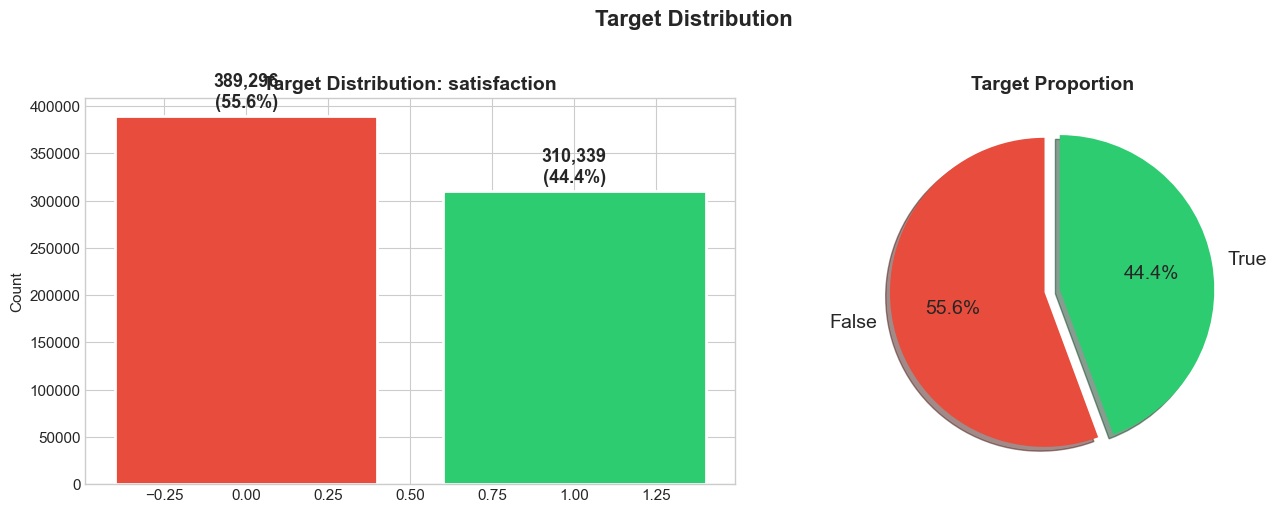


Imbalance Ratio: 1.3:1 (for every 1 satisfied customer, there are 1.3 dissatisfied customers)


In [6]:
# === TARGET DISTRIBUTION ===
# Create a numeric version of the target (needed for analysis)
train['target'] = (train['satisfaction'] == True).astype(int)

target_counts = train['satisfaction'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart - shows absolute numbers
colors = ['#e74c3c', '#2ecc71']
bars = axes[0].bar(target_counts.index, target_counts.values, color=colors,
                   edgecolor='white', linewidth=2)
axes[0].set_title('Target Distribution: satisfaction')
axes[0].set_ylabel('Count')
for bar, val in zip(bars, target_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 5000,
                f'{val:,}\n({val/len(train)*100:.1f}%)',
                ha='center', va='bottom', fontweight='bold', fontsize=13)

# Pie chart - shows proportions
axes[1].pie(target_counts.values, labels=target_counts.index,
            autopct='%1.1f%%', colors=colors, startangle=90,
            explode=(0.05, 0.05), shadow=True, textprops={'fontsize': 14})
axes[1].set_title('Target Proportion')

plt.suptitle('Target Distribution', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

ratio = target_counts[0] / target_counts[1]
print(f'\nImbalance Ratio: {ratio:.1f}:1 (for every 1 satisfied customer, there are {ratio:.1f} dissatisfied customers)')

### Target Imbalance Implications

> 55.6% **False**     ~44.4% **True**     **Ratio is 1.3:1.** 

---
## Numeric Feature Distributions

> 1. **Shape** — normal, skewed, uniform, bimodal?  
> 2. **Range** — are there outliers?  
> 3. **Separation** — does the distribution SHIFT between target classes?

### Class Separation Analysis
If they separate → the feature is predictive.  
If they overlap completely → the feature is weak.

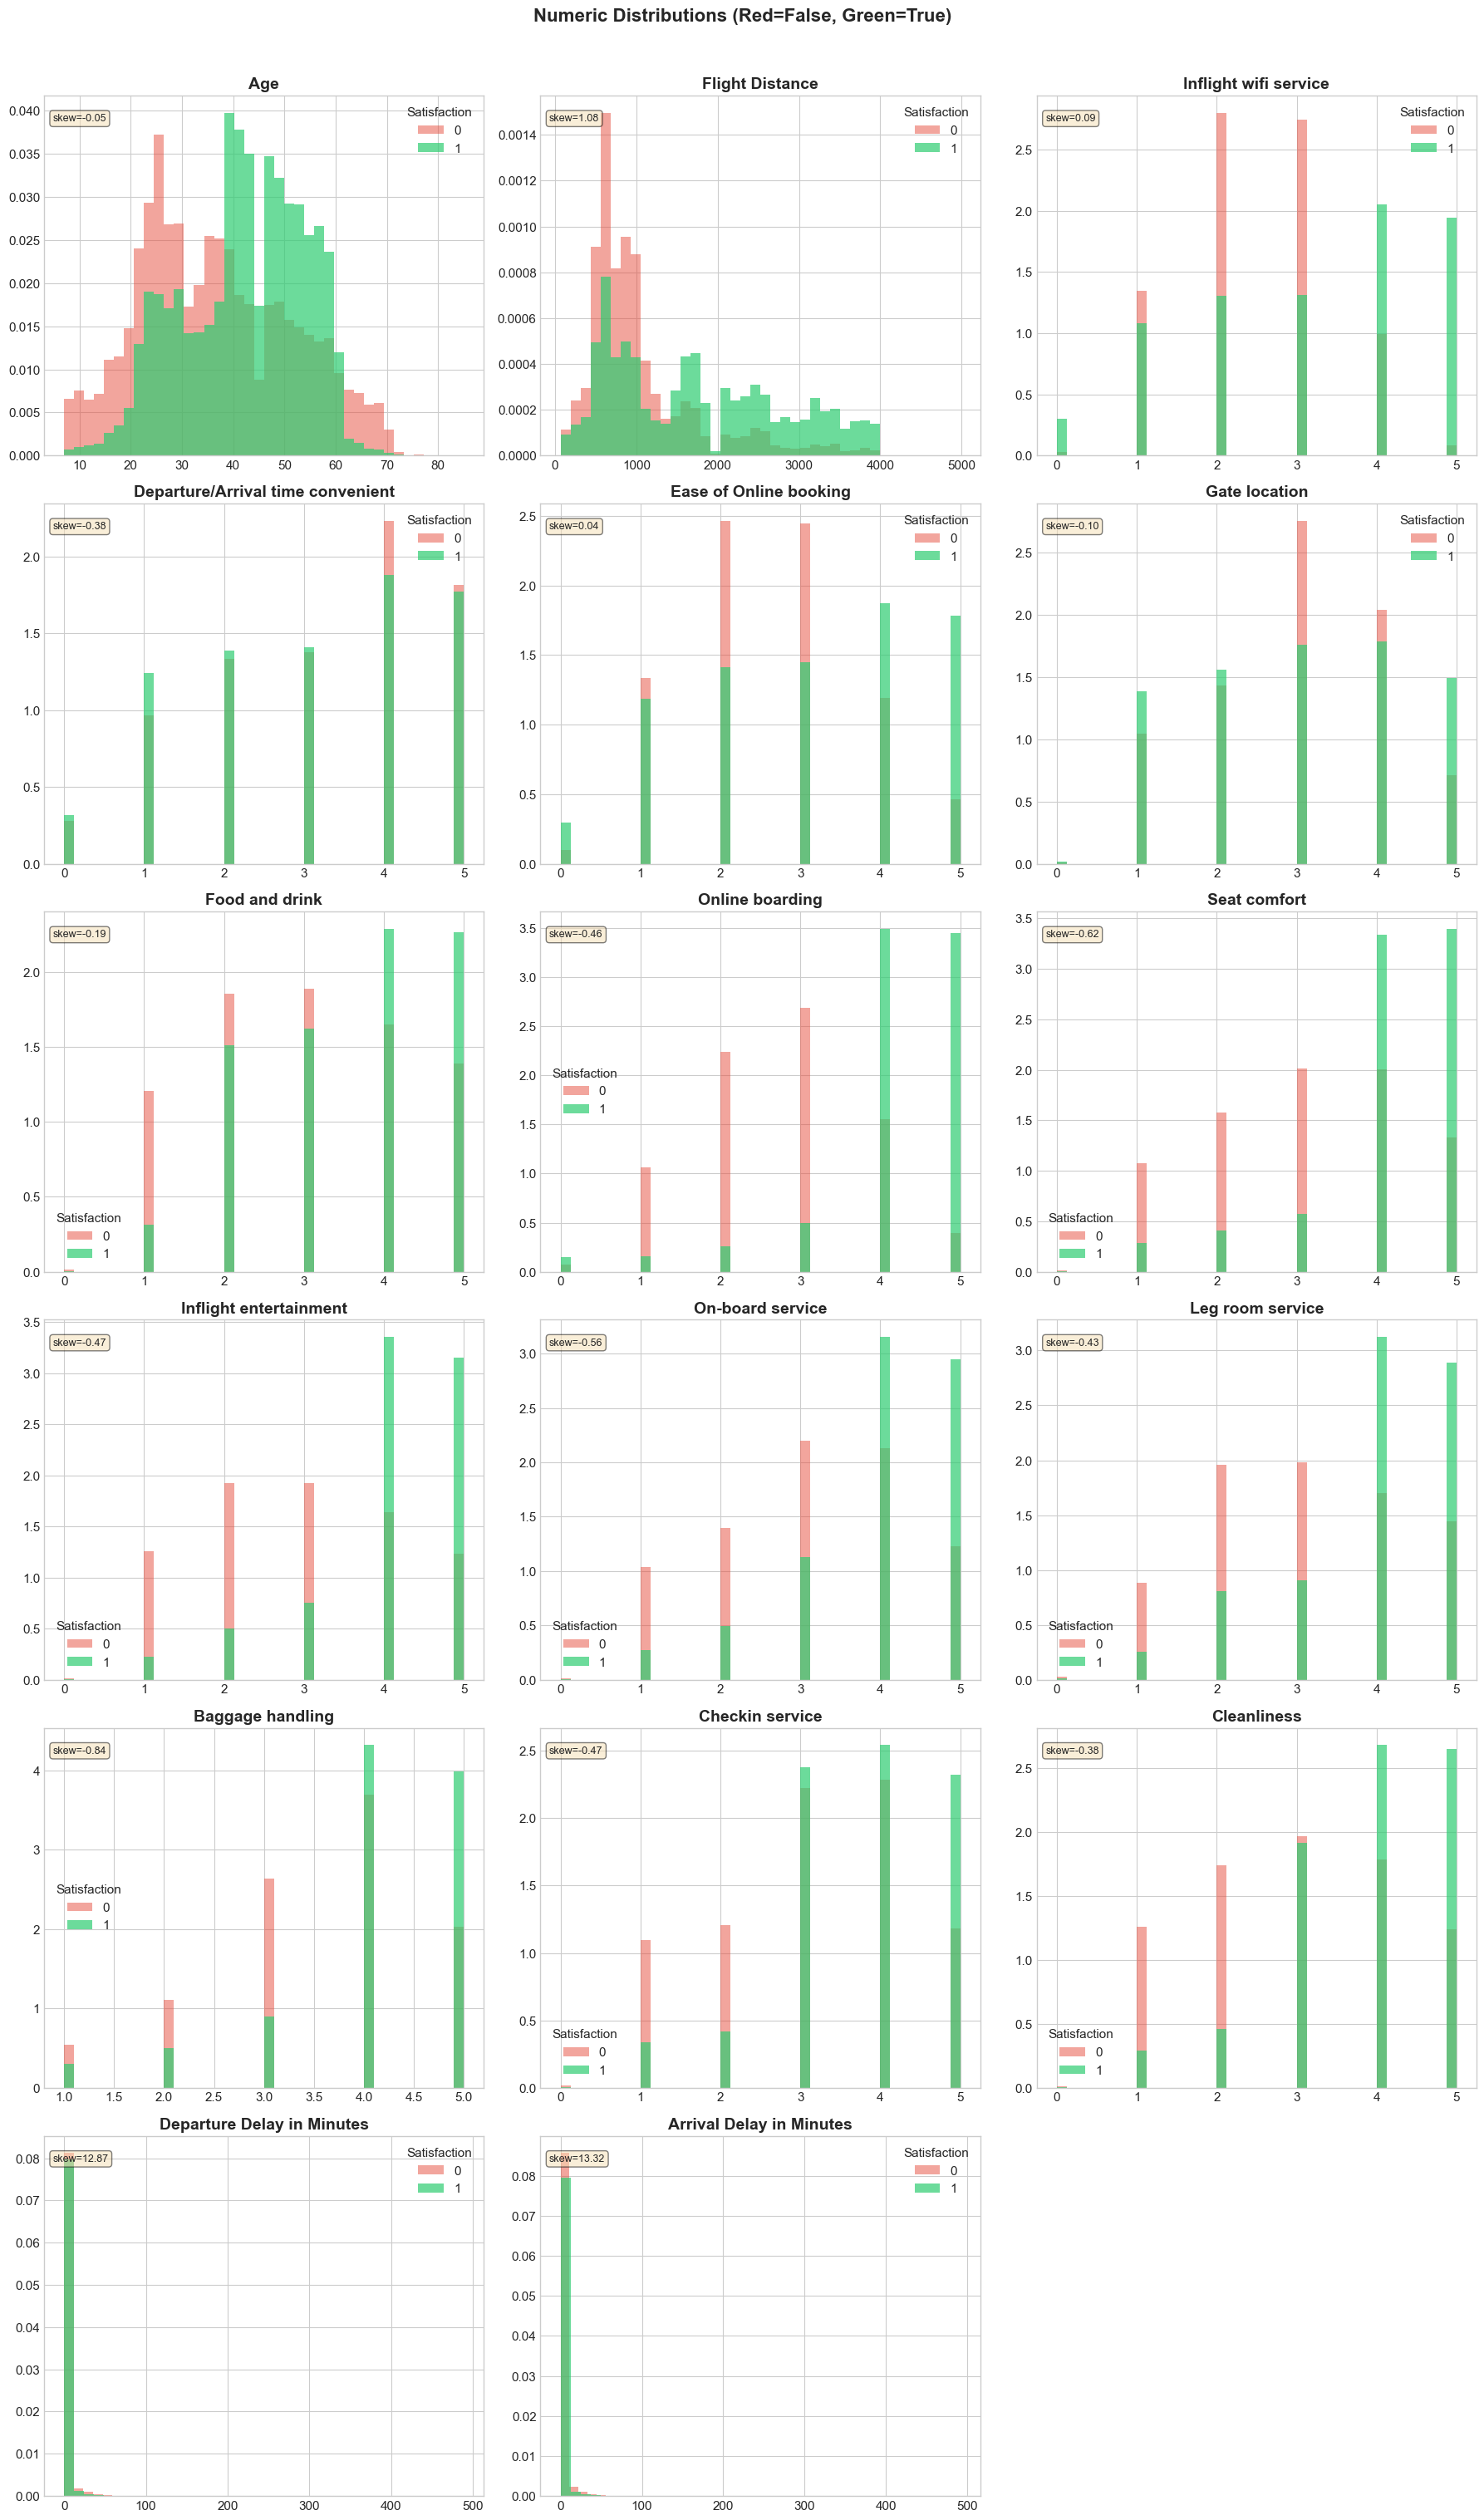

In [7]:
# === NUMERIC DISTRIBUTIONS COLORED BY TARGET ===
numeric_cols = [col for col in train.select_dtypes(include=['int', 'float']).columns.tolist() if col not in['id', 'target']]

fig, axes = plt.subplots(6, 3, figsize=(18, 30))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    ax = axes[i]

    # THE KEY TECHNIQUE: Plot both classes on the same axis
    for label, color, alpha in [(0, '#e74c3c', 0.5), (1, '#2ecc71', 0.7)]:
        subset = train[train['target'] == label][col]
        ax.hist(subset, bins=40, alpha=alpha, color=color, label=label, density=True)

    ax.set_title(f'{col}', fontweight='bold')
    ax.legend(title='Satisfaction')

    # Add skewness - tells you if the distribution is lopsided
    skew = train[col].skew()
    ax.text(0.02, 0.95, f'skew={skew:.2f}',
            transform=ax.transAxes, fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Numeric Distributions (Red=False, Green=True)',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### Numeric Distribution Insights

#### Question 1: "Does the green (Yes) shift away from the red (No)?"

| Feature | Shift? | What you see |
|---------|--------|-------------|
| **Age** | **Yes** | Green piles up mostly at 40-60, Red piles up mostly at younger and older people|
| **Ratings** | **Slight** | Green piles up mostly at 4-5 and red ones piles up mostly at 2-3|
| **Flight Distance** | **No** | There is no particular shift at targets|
| **Delays** | **No** | There is no particular shift at targets|

#### Question 2: "Is it skewed?"

| Feature | Skew | Action |
|---------|------|--------|
| Age | ~0 (symmetric) | No transform needed |
| Flight Distance | Right-skewed (1.08) | `log(distance)` transform can be helpful|
| Delays | Right-skewed (~13) | Outlier transformation|

#### Question 3: "Are there discrete jumps?"

| Feature | Pattern | Action |
|---------|---------|--------|
| Ratings | Only values 1-5 | **Ordinal categorical** |

---

> **Key Takeaways:** Interactions between ratings and flight distance can be useful. Delay features have outliers.

In [8]:
num_but_cat_cols = [col for col in numeric_cols if col not in['Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']]

---
## Categorical Target Rate Analysis

> **"Target rate by category"**  

### How To Read The Chart
- **Red dashed line** = overall average (44.4%)
- Categories **RIGHT of the line** → INCREASE satisfaction probability
- Categories **LEFT of the line** → DECREASE satisfaction probability
- **FAR from the line** → Strong signal
- **Close to the line** → Weak signal

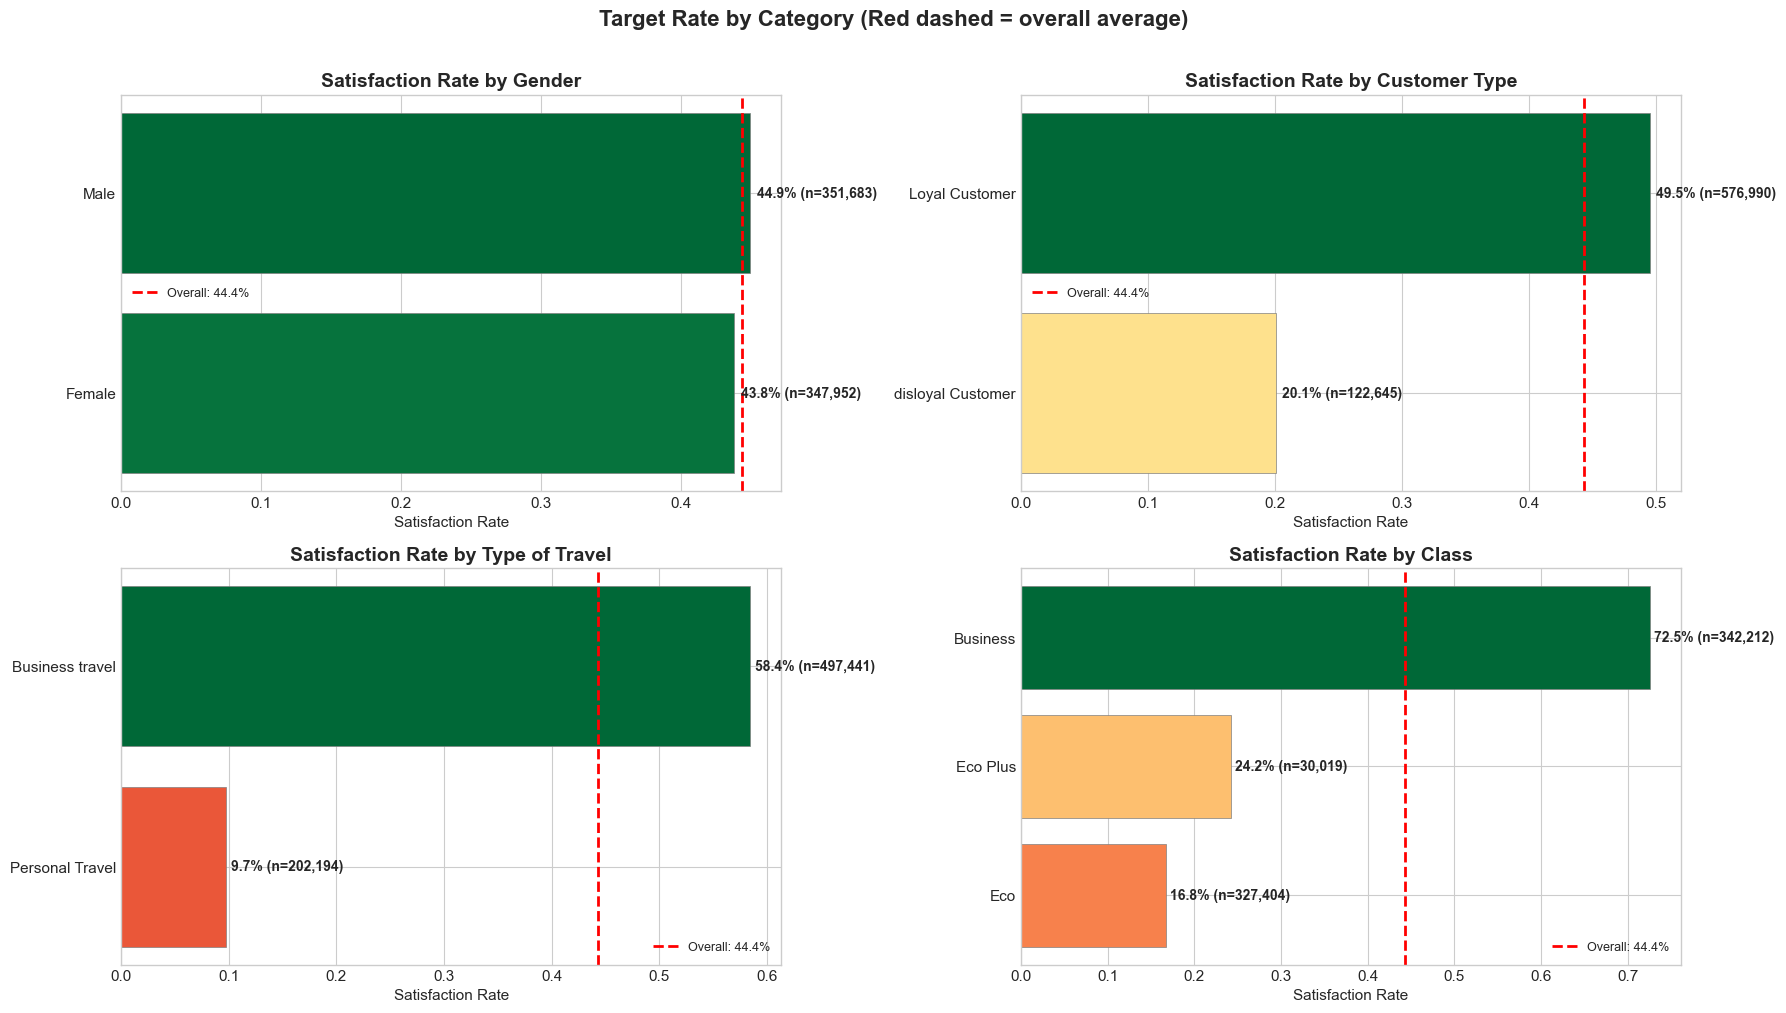

In [9]:
# === TARGET RATE BY EACH CATEGORICAL FEATURE ===
cat_cols = [col for col in train.select_dtypes(exclude=['int', 'float']).columns.tolist() if col not in['id', 'target', 'satisfaction']]

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    ax = axes[i]

    # Calculate target rate per category
    rates = train.groupby(col)['target'].agg(['mean', 'count']).reset_index()
    rates.columns = [col, 'satisfaction_rate', 'count']
    rates = rates.sort_values('satisfaction_rate', ascending=True)

    # Horizontal bar chart — sorted by satisfaction rate
    bars = ax.barh(rates[col], rates['satisfaction_rate'],
                   color=plt.cm.RdYlGn(rates['satisfaction_rate'] / max(rates['satisfaction_rate'].max(), 0.01)),
                   edgecolor='gray', linewidth=0.5)

    # Add labels with rate AND sample size
    for bar, rate, count in zip(bars, rates['satisfaction_rate'], rates['count']):
        ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2.,
                f'{rate:.1%} (n={count:,})', va='center', fontsize=10, fontweight='bold')

    # RED DASHED LINE = overall average
    baseline = train['target'].mean()
    ax.axvline(x=baseline, color='red', linestyle='--', linewidth=2,
               label=f'Overall: {baseline:.1%}')

    ax.set_title(f'Satisfaction Rate by {col}', fontweight='bold')
    ax.set_xlabel('Satisfaction Rate')
    ax.legend(fontsize=9)

plt.suptitle('Target Rate by Category (Red dashed = overall average)',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### Categorical Target Rate Findings

#### **Class** — STRONG
- **Eco: 16.8%** → **Eco Plus: 24.2%** → **Business: 72.5%**

> **What this means:** Being at Business class gives high satisfaction.

#### **Type of Travel** — STRONG
- **Business: 58.4%** vs **Personal: 9.7%**

> **What this means:** Personal travellers have low satisfaction.

#### **Customer Type** — GOOD
- **Loyal: 49.5%** vs **Disloyal: 20.1%**

> **What this means:** Disloyal travellers have low satisfaction.

#### **Gender** — ALMOST USELESS
- All categories between 43.8% and 43.9%

> **What this means:** Gender barely moves the needle.

---
## Feature Interactions — Finding Non-Linear Signals

### How To Read Interaction Heatmaps

- Each cell = satisfaction rate for that **specific combination**
- **Green** = high satisfaction rate
- **Red/Dark** = low satisfaction rate
- If **all rows look the same** → No interaction
- If **rows look VERY different** → STRONG interaction! → **A FEATURE CANDIDATE!**

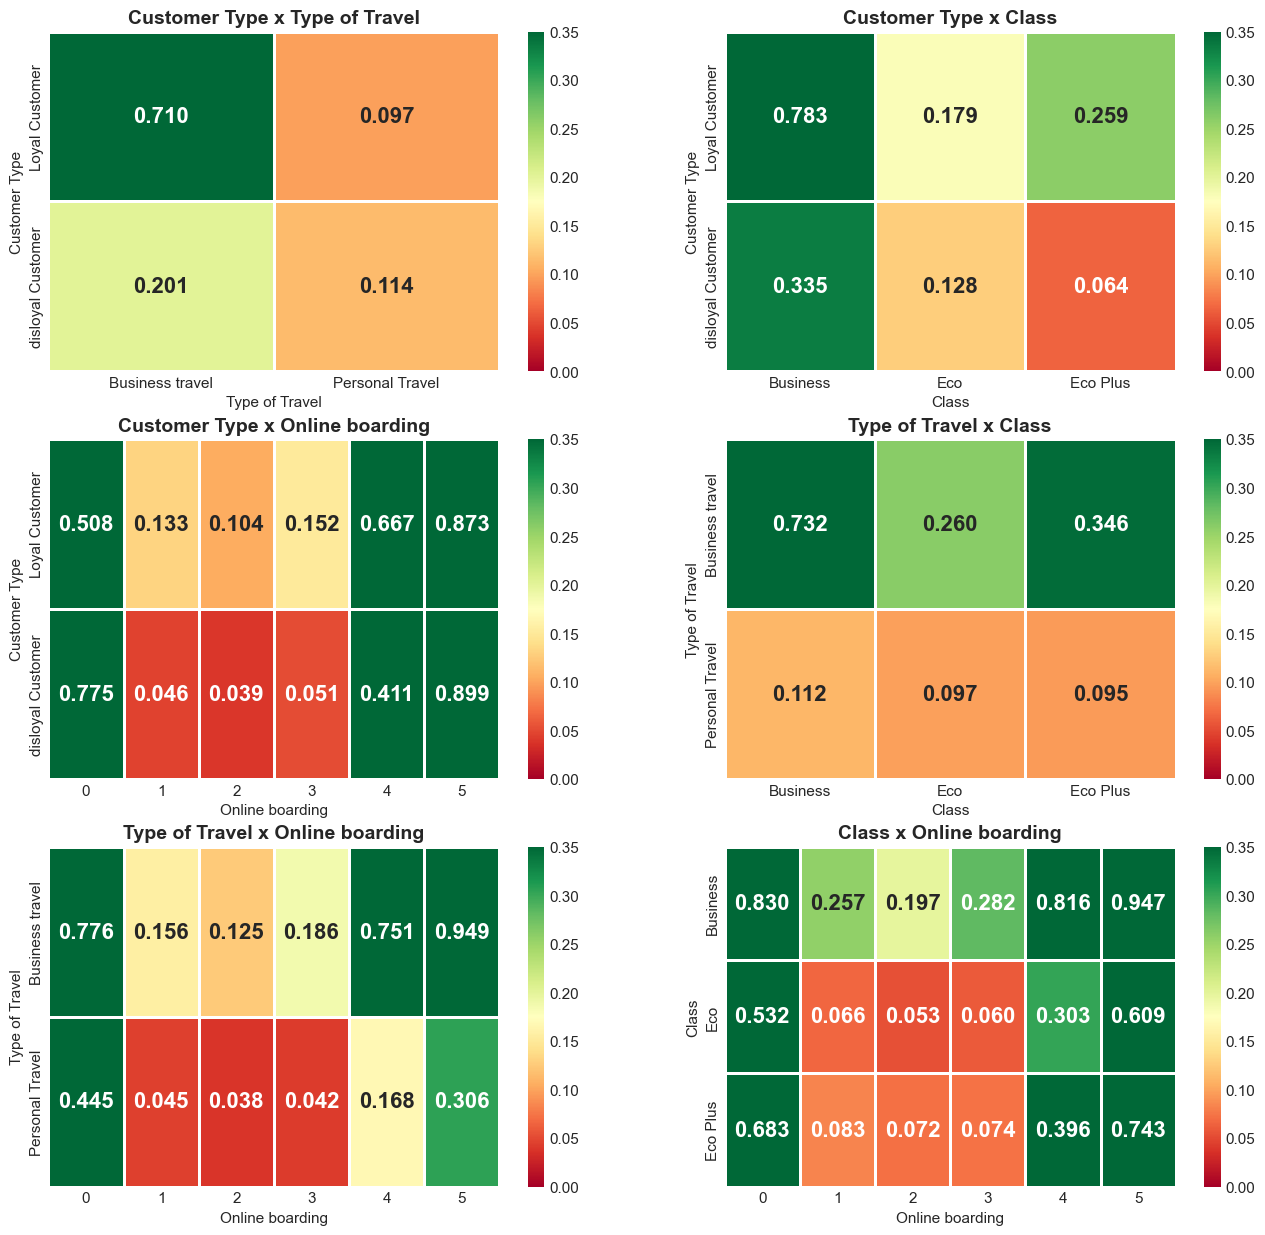

In [10]:
from itertools import combinations

sel_cols = [col for col in cat_cols if col not in['Gender']] + ['Online boarding']
combination_list = list(combinations(sel_cols, 2))
n = len(combination_list)//2 + len(combination_list)%2
fig, axes = plt.subplots(n, 2, figsize=(16, 5*n))
x,y = 0,0
for idx,(col1,col2) in enumerate(combination_list):
    ct = pd.crosstab(train[col1], train[col2],
                    values=train['target'], aggfunc='mean')
    sns.heatmap(ct, annot=True, fmt='.3f', cmap='RdYlGn', ax=axes[y, x],
                linewidths=2, linecolor='white', annot_kws={'size': 16, 'weight': 'bold'},
                vmin=0, vmax=0.35)
    axes[y, x].set_title(f'{col1} x {col2}', fontweight='bold')
    x+=1
    if x==2:
        y+=1
        x=0
plt.show()

---
## Numeric Features vs Target (Box Plots)

> Small overlap between boxes = feature separates Yes and No well.  
> Large overlap = feature doesn't help distinguish.

**Key metric:** Look at the `Δmean` (% difference in means between Yes and No).  
- `|Δmean| > 10%` → Strong feature (shown in **green**)
- `|Δmean| < 10%` → Weak feature (shown in gray)

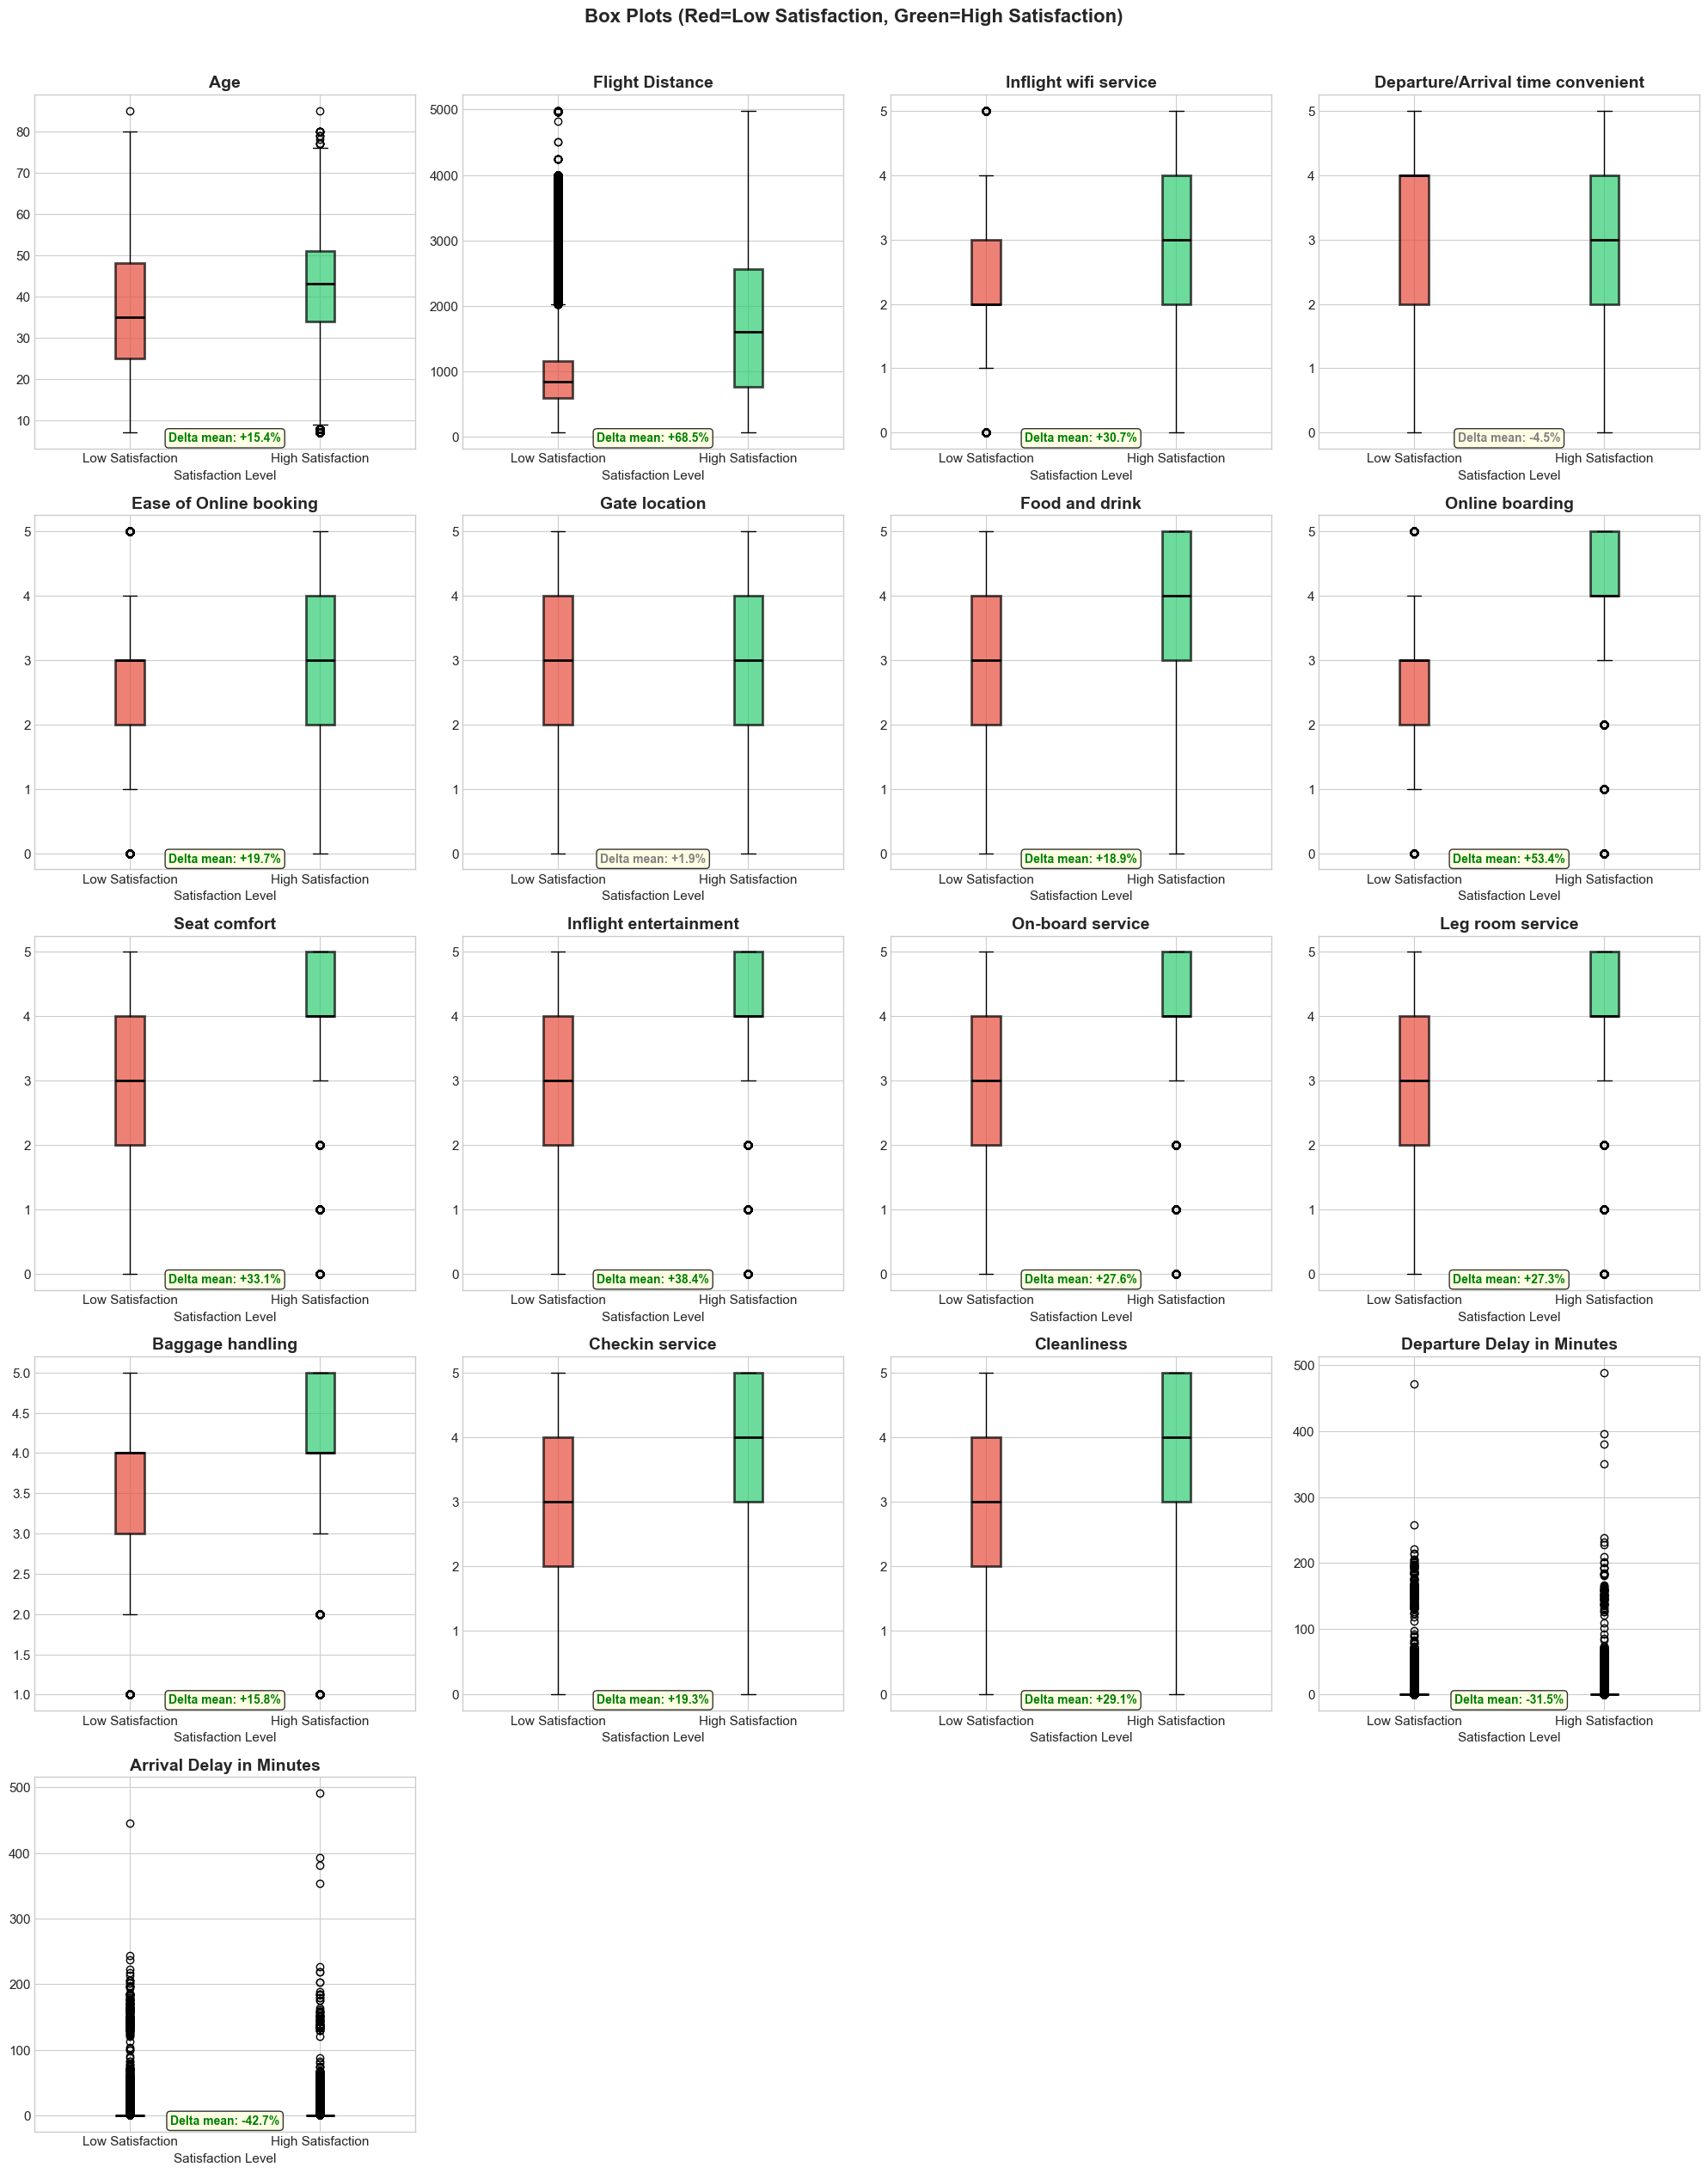

In [11]:
# === BOX PLOTS: Numeric Features vs Target ===
n = len(numeric_cols)//4 + len(numeric_cols)%4
fig, axes = plt.subplots(n, 4, figsize=(20, n*5))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    ax = axes[i]

    data_no = train[train['target']== 0][col].dropna()
    data_yes = train[train['target']== 1][col].dropna()

    bp = ax.boxplot([data_no, data_yes], labels=['Low Satisfaction', 'High Satisfaction'],
                    patch_artist=True,
                    boxprops=dict(linewidth=2),
                    medianprops=dict(linewidth=2, color='black'))
    bp['boxes'][0].set_facecolor('#e74c3c')
    bp['boxes'][0].set_alpha(0.7)
    bp['boxes'][1].set_facecolor('#2ecc71')
    bp['boxes'][1].set_alpha(0.7)

    ax.set_title(f'{col}', fontweight='bold')
    ax.set_xlabel('Satisfaction Level')

    # Calculate and display the difference
    mean_no = data_no.mean()
    mean_yes = data_yes.mean()
    diff_pct = (mean_yes - mean_no) / mean_no * 100
    color = 'green' if abs(diff_pct) > 10 else 'gray'
    ax.text(0.5, 0.02, f'Delta mean: {diff_pct:+.1f}%', transform=ax.transAxes,
            ha='center', fontsize=10, fontweight='bold', color=color,
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Box Plots (Red=Low Satisfaction, Green=High Satisfaction)',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### What the Box Plots Show

The high-satisfaction group generally has higher service-rating scores and travels farther. The largest positive differences in group means are for **Flight Distance (+68.5%)** and **Online boarding (+53.4%)**. Age is also higher in the satisfied group (+15.4%), although the distributions overlap.

| Feature | Delta mean |
|---|---:|
| Flight Distance | +68.5% |
| Online boarding | +53.4% |
| Inflight entertainment | +38.4% |
| Seat comfort | +33.1% |
| Inflight wifi service | +30.7% |
| Cleanliness | +29.1% |
| On-board service | +27.6% |
| Leg room service | +27.3% |
| Ease of Online booking | +19.7% |
| Checkin service | +19.3% |
| Food and drink | +18.9% |
| Baggage handling | +15.8% |
| Age | +15.4% |
| Gate location | +1.9% |
| Departure/Arrival time convenient | -4.5% |
| Departure Delay in Minutes | -31.5% |
| Arrival Delay in Minutes | -42.7% |

Gate location and time convenience show little difference between groups. The delay means are lower for satisfied passengers, but both delay distributions are strongly right-skewed, with most observations near zero and many high-delay outliers. These differences may be driven by the long tails, so compare robust statistics before treating delays as a reliable signal.

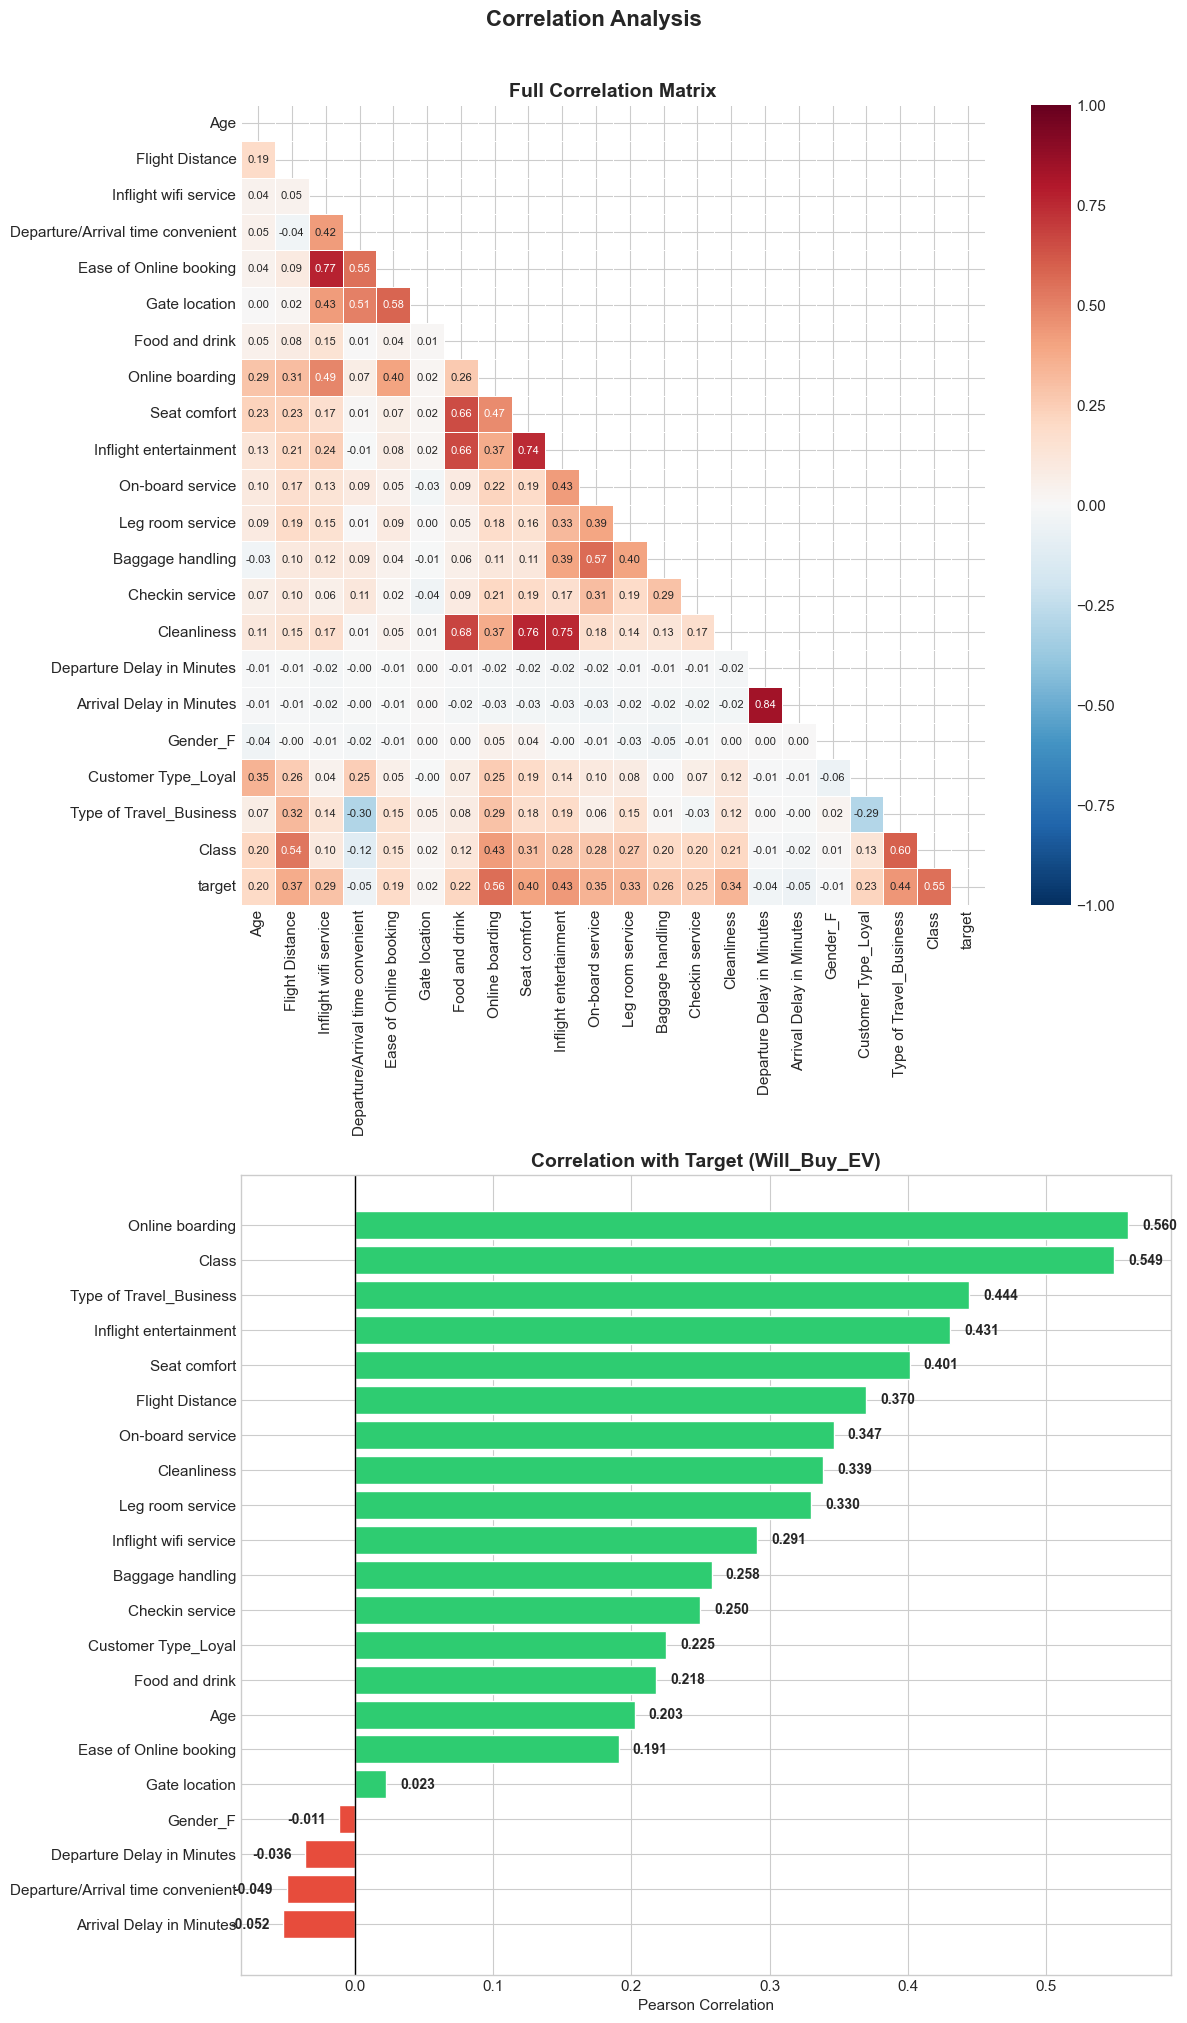

In [15]:
# === CORRELATION ANALYSIS ===
# First, encode categoricals so we can compute correlation
train_encoded = train.copy()
train_encoded['Gender_F'] = (train['Gender'] == 'Female').astype(int)
train_encoded['Customer Type_Loyal'] = (train['Customer Type'] == 'Loyal Customer').astype(int)
train_encoded['Type of Travel_Business'] = (train['Type of Travel'] == 'Business travel').astype(int)
train_encoded['Class'] = train['Class'].map({'Eco': 0, 'Eco Plus': 1, 'Business': 2})

corr_cols = ['Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender_F',
       'Customer Type_Loyal', 'Type of Travel_Business', 'Class','target']

corr_matrix = train_encoded[corr_cols].corr()

fig, axes = plt.subplots(2, 1, figsize=(12, 20))

# LEFT: Full correlation heatmap
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, ax=axes[0], linewidths=0.5, annot_kws={'size': 8},
            vmin=-1, vmax=1)
axes[0].set_title('Full Correlation Matrix', fontweight='bold')

# RIGHT: Target correlation bar chart (MOST USEFUL!)
target_corr = corr_matrix['target'].drop('target').sort_values()
colors = ['#2ecc71' if x > 0 else '#e74c3c' for x in target_corr.values]
axes[1].barh(target_corr.index, target_corr.values, color=colors, edgecolor='white')
axes[1].axvline(x=0, color='black', linewidth=1)
axes[1].set_title('Correlation with Satisfaction', fontweight='bold')
axes[1].set_xlabel('Pearson Correlation')

for idx, (val, name) in enumerate(zip(target_corr.values, target_corr.index)):
    axes[1].text(val + (0.01 if val > 0 else -0.01), idx, f'{val:.3f}',
                va='center', ha='left' if val > 0 else 'right',
                fontweight='bold', fontsize=10)

plt.suptitle('Correlation Analysis', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### Correlation Insights

The lower chart ranks each feature by its **Pearson correlation with passenger satisfaction**. Positive values are associated with `True` (satisfied); negative values are associated with `False` (not satisfied). Values closer to zero indicate a weaker *linear* association, not necessarily no predictive value.

| Rank | Feature | Correlation |
|---:|---|---:|
| 1 | Online boarding | +0.560 |
| 2 | Class | +0.549 |
| 3 | Type of Travel (Business) | +0.444 |
| 4 | Inflight entertainment | +0.431 |
| 5 | Seat comfort | +0.401 |
| 6 | Flight Distance | +0.370 |
| 7 | On-board service | +0.347 |
| 8 | Cleanliness | +0.339 |
| 9 | Leg room service | +0.330 |
| 10 | Inflight WiFi service | +0.291 |

Online boarding and flight class have the strongest positive linear relationships with satisfaction in this chart. Departure and arrival delays have weak negative correlations (-0.036 and -0.052); gender (-0.011), gate location (+0.023), and time convenience (-0.049) are also close to zero.

The upper heatmap also shows that some service ratings move together—for example, WiFi service and ease of online booking (+0.77), seat comfort and cleanliness (+0.76), and seat comfort and inflight entertainment (+0.74). This overlap means those features may carry partly redundant information.

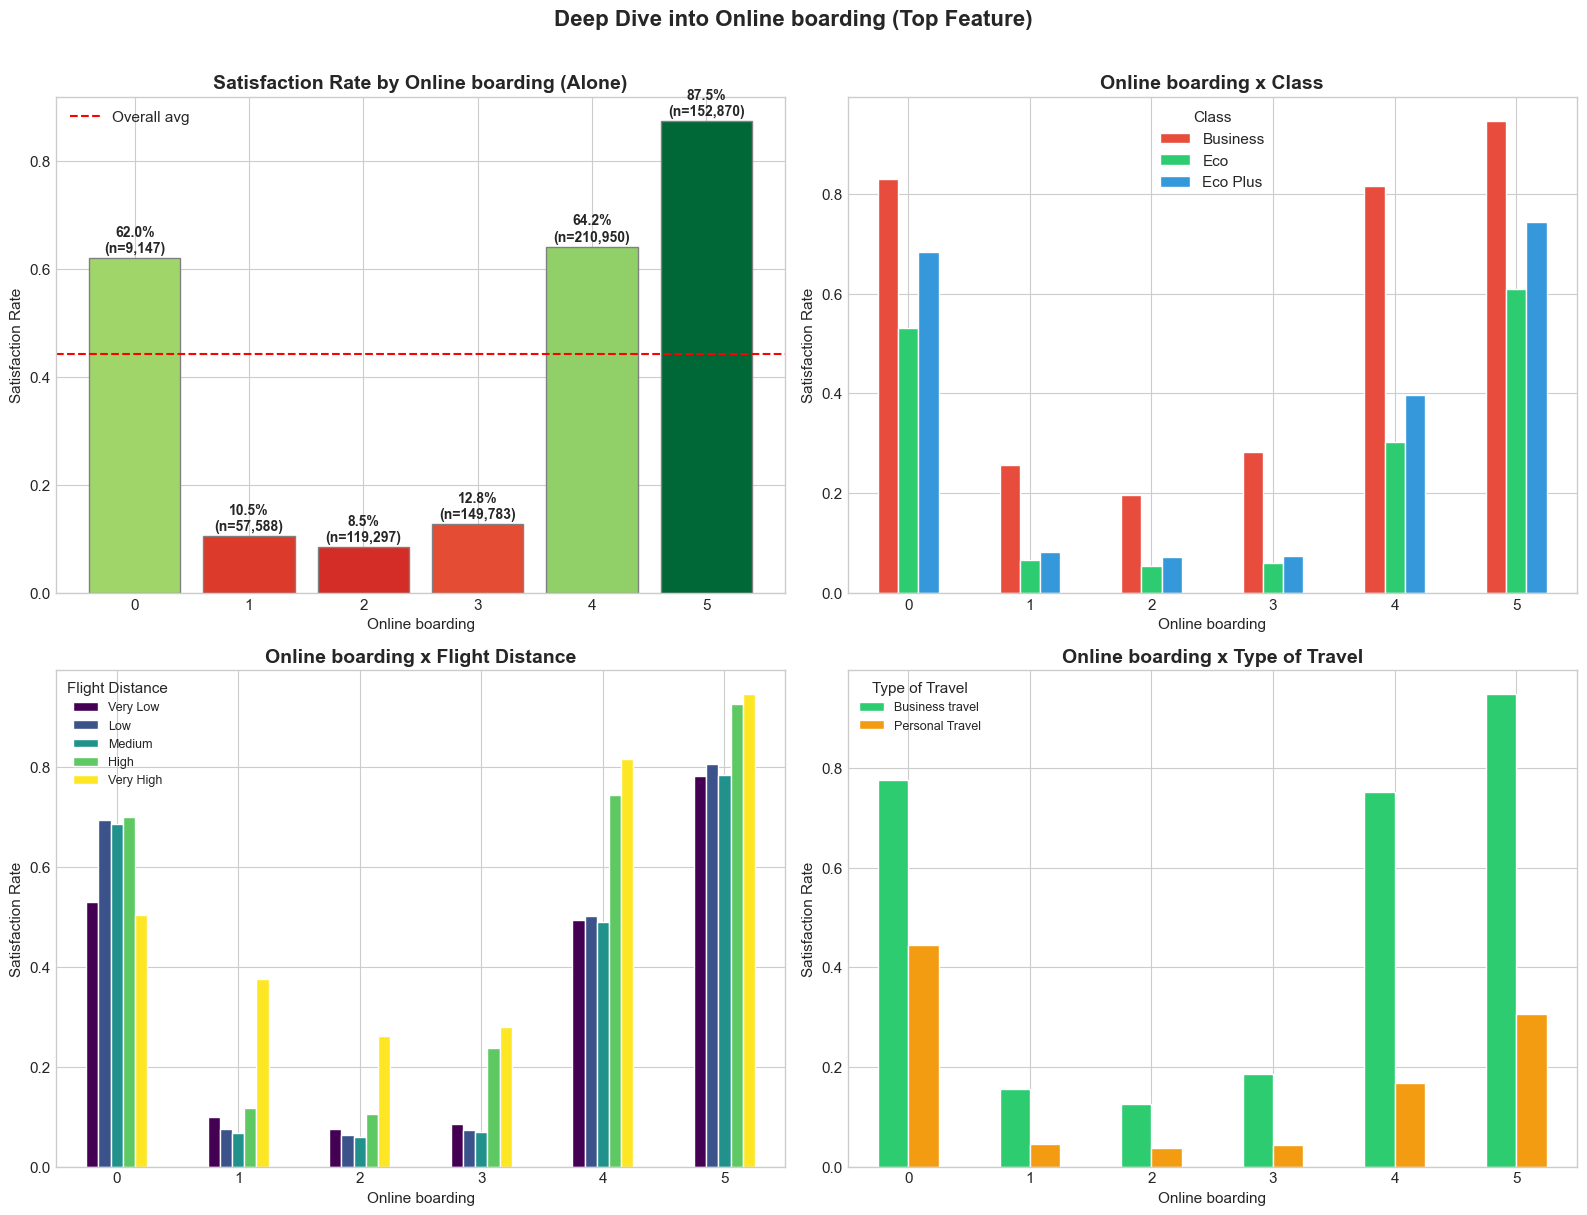

In [24]:
# === DEEP DIVE: Online boarding ===
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# PLOT 1: Satisfaction rate by Online boarding (alone)
concern_rates = train.groupby('Online boarding')['target'].agg(['mean', 'count']).reset_index()
bars = axes[0, 0].bar(concern_rates['Online boarding'],
                       concern_rates['mean'],
                       color=plt.cm.RdYlGn(concern_rates['mean'] / concern_rates['mean'].max()),
                       edgecolor='gray')
for bar, rate, count in zip(bars, concern_rates['mean'], concern_rates['count']):
    axes[0, 0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                    f'{rate:.1%}\n(n={count:,})', ha='center', fontweight='bold', fontsize=10)
axes[0, 0].set_xlabel('Online boarding')
axes[0, 0].set_ylabel('Satisfaction Rate')
axes[0, 0].set_title('Satisfaction Rate by Online boarding (Alone)', fontweight='bold')
axes[0, 0].axhline(y=train['target'].mean(), color='red', linestyle='--', label='Overall avg')
axes[0, 0].legend()

# PLOT 2: Online boarding x Class
concern_subsidy = train.groupby(['Online boarding', 'Class'])['target'].mean().unstack()
concern_subsidy.plot(kind='bar', ax=axes[0, 1], color=['#e74c3c', '#2ecc71', '#3498db'], edgecolor='white')
axes[0, 1].set_title('Online boarding x Class', fontweight='bold')
axes[0, 1].set_xlabel('Online boarding')
axes[0, 1].set_ylabel('Satisfaction Rate')
axes[0, 1].legend(title='Class')
axes[0, 1].tick_params(axis='x', rotation=0)

# PLOT 3: Online boarding x Flight Distance
income_bins = pd.qcut(train['Flight Distance'], 5, labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'])
concern_income = train.groupby([train['Online boarding'].astype(int), income_bins])['target'].mean().unstack()
concern_income.plot(kind='bar', ax=axes[1, 0], colormap='viridis', edgecolor='white')
axes[1, 0].set_title('Online boarding x Flight Distance', fontweight='bold')
axes[1, 0].set_xlabel('Online boarding')
axes[1, 0].set_ylabel('Satisfaction Rate')
axes[1, 0].legend(title='Flight Distance', fontsize=9)
axes[1, 0].tick_params(axis='x', rotation=0)

# PLOT 4: Online boarding x Type of Travel
temp = train.groupby([train['Online boarding'].astype(int), 'Type of Travel'])['target'].mean().unstack()
temp = temp[['Business travel', 'Personal Travel']]
temp.plot(kind='bar', ax=axes[1, 1], color=['#2ecc71', '#f39c12'], edgecolor='white')
axes[1, 1].set_title('Online boarding x Type of Travel', fontweight='bold')
axes[1, 1].set_xlabel('Online boarding')
axes[1, 1].set_ylabel('Satisfaction Rate')
axes[1, 1].legend(title='Type of Travel', fontsize=9)
axes[1, 1].tick_params(axis='x', rotation=0)

plt.suptitle('Deep Dive into Online boarding (Top Feature)',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### What the Online Boarding Plots Show

The top-left chart shows a strong, but not perfectly monotonic, association between the online-boarding rating and satisfaction. Ratings **1–3** have low satisfaction rates (8.5%–12.8%), while rating **4** rises to 64.2% and rating **5** to 87.5%. Rating **0** is also high at 62.0%; because 0 may mean unrated rather than a low score, interpret it separately. The dashed line marks the overall satisfaction rate (about 44.4%).

| Online boarding rating | Satisfaction rate | Passengers |
|---:|---:|---:|
| 0 | 62.0% | 9,147 |
| 1 | 10.5% | 57,588 |
| 2 | 8.5% | 119,297 |
| 3 | 12.8% | 149,783 |
| 4 | 64.2% | 210,950 |
| 5 | 87.5% | 152,870 |

The other panels suggest that this relationship varies by passenger group:

- **Class:** Business-class passengers generally have higher satisfaction rates than Eco passengers at the same boarding rating. For ratings 4 and 5, rates rise across all three classes.
- **Flight distance:** At ratings 4 and 5, the longer-distance bins tend to have higher rates. The pattern is less consistent at ratings 0–3.
- **Type of travel:** Business travelers have higher rates than personal travelers at every boarding rating; the gap is especially visible at ratings 4 and 5.

---
## Train vs Test Distribution Check

### What To Look For:
- **Histograms match** → Safe, your CV score is reliable
- **Histograms differ** → Danger! Need adversarial validation or time-based splits

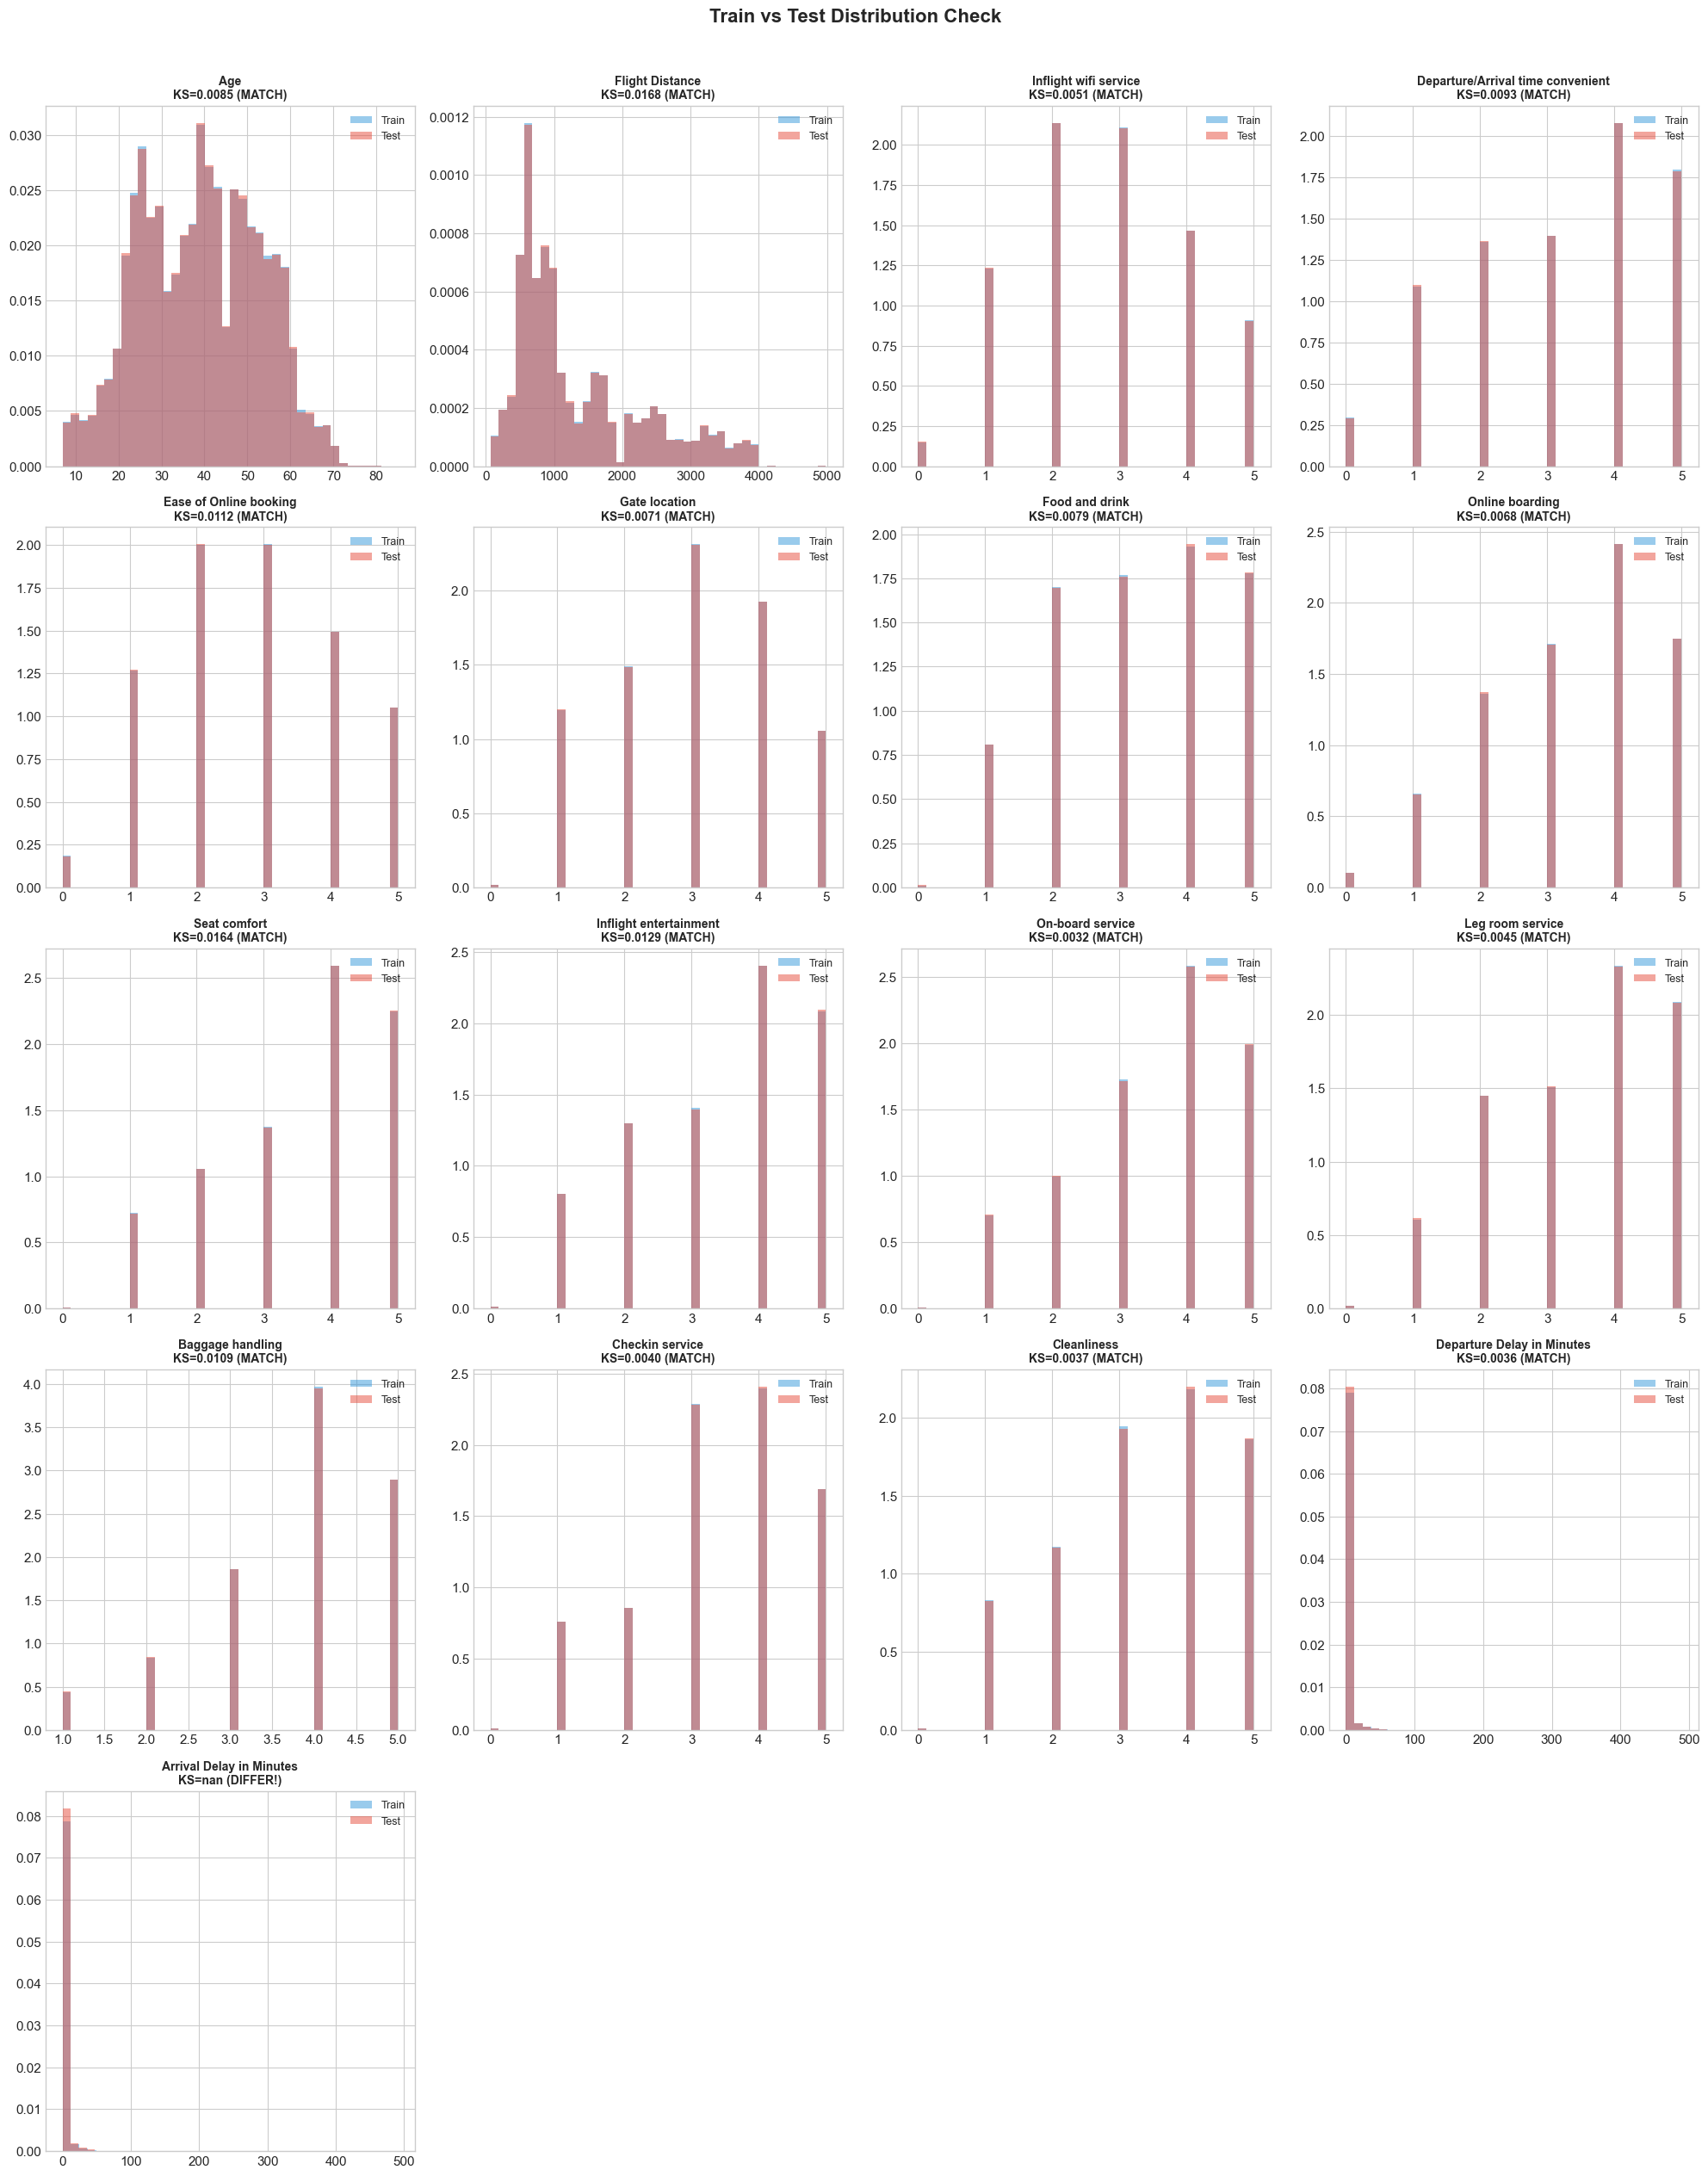


Categorical Distribution Comparison (Train vs Test):
  Gender                         max_diff=0.0015 [OK]
  Customer Type                  max_diff=0.0014 [OK]
  Type of Travel                 max_diff=0.0002 [OK]
  Class                          max_diff=0.0004 [OK]
  Inflight wifi service          max_diff=0.0004 [OK]
  Departure/Arrival time convenient max_diff=0.0014 [OK]
  Ease of Online booking         max_diff=0.0006 [OK]
  Gate location                  max_diff=0.0004 [OK]
  Food and drink                 max_diff=0.0015 [OK]
  Online boarding                max_diff=0.0011 [OK]
  Seat comfort                   max_diff=0.0014 [OK]
  Inflight entertainment         max_diff=0.0014 [OK]
  On-board service               max_diff=0.0013 [OK]
  Leg room service               max_diff=0.0011 [OK]
  Baggage handling               max_diff=0.0015 [OK]
  Checkin service                max_diff=0.0013 [OK]
  Cleanliness                    max_diff=0.0021 [OK]


In [29]:
# === TRAIN vs TEST DISTRIBUTIONS ===
n = len(numeric_cols)//4 + len(numeric_cols)%4
fig, axes = plt.subplots(n, 4, figsize=(20, n*5))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    ax = axes[i]
    ax.hist(train[col], bins=40, alpha=0.5, color='#3498db', label='Train', density=True)
    ax.hist(test[col], bins=40, alpha=0.5, color='#e74c3c', label='Test', density=True)

    # KS test: measures how different two distributions are
    ks_stat, ks_pval = stats.ks_2samp(
        train[col].sample(10000, random_state=42),
        test[col].sample(10000, random_state=42)
    )

    status = 'MATCH' if ks_pval > 0.05 else 'DIFFER!'
    ax.set_title(f'{col}\nKS={ks_stat:.4f} ({status})', fontweight='bold', fontsize=10)
    ax.legend(fontsize=9)

for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Train vs Test Distribution Check',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Also check categoricals
print('\nCategorical Distribution Comparison (Train vs Test):')

for col in cat_cols+num_but_cat_cols:
    train_dist = train[col].value_counts(normalize=True).sort_index()
    test_dist = test[col].value_counts(normalize=True).sort_index()
    max_diff = (train_dist - test_dist).abs().max()
    status = 'OK' if max_diff < 0.01 else 'CHECK!'
    print(f'  {col:30s} max_diff={max_diff:.4f} [{status}]')

---
## Train, Test and Original Distribution Check

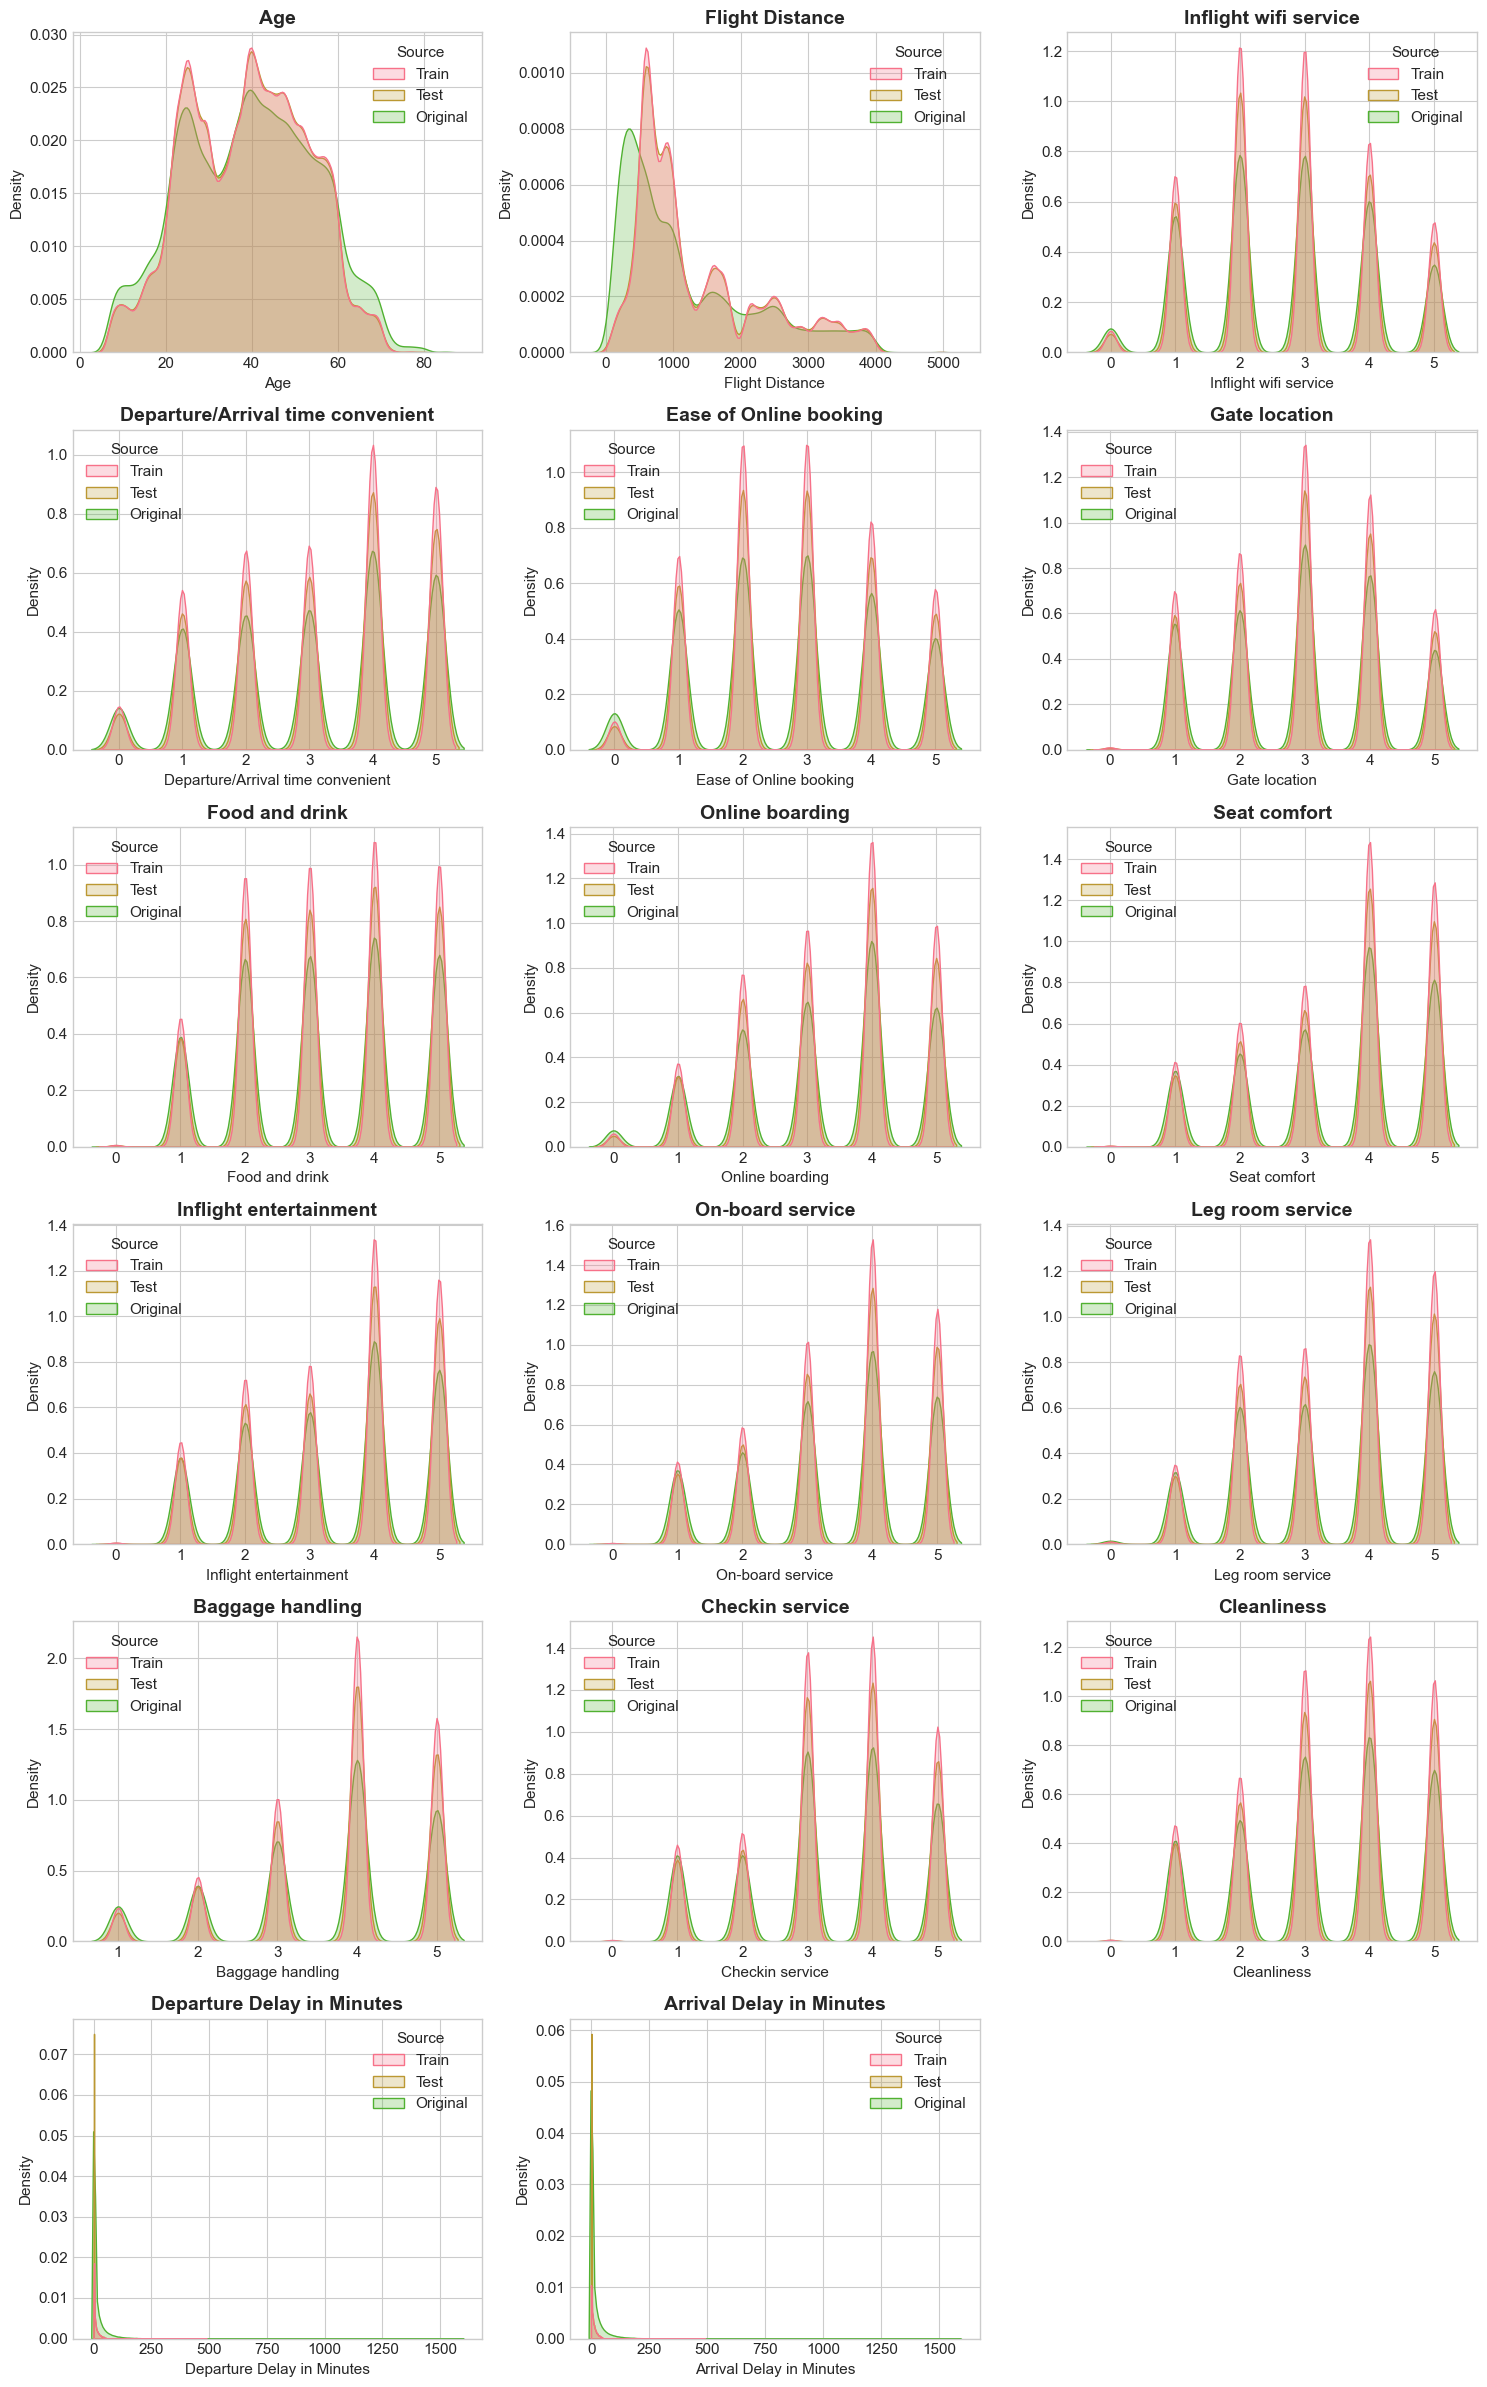

In [31]:
df_plot = pd.concat([
    train[numeric_cols].assign(Source='Train'),
    test[numeric_cols].assign(Source='Test'),
    original[numeric_cols].assign(Source='Original')
], ignore_index=True)

n_cols = 3
n_rows = (len(numeric_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.kdeplot(data=df_plot, x=col, hue='Source', ax=axes[i], 
                fill=True, common_norm=False, warn_singular=False)
    axes[i].set_title(col)

for i in range(len(numeric_cols), len(axes)):
    axes[i].axis('off')

plt.tight_layout()
plt.show()

del df_plot